In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
torch.manual_seed(42)

X, y = make_classification(n_samples=1000, n_features=3, n_informative=3, n_redundant=0, random_state=42)
#n_informative means no additional noisy features which are not related to output and n_redundant means no linearly dependant features.
print(X)
print(X.shape)
print(y)
print(y.shape)

[[ 0.52170639  0.72685697  2.50410248]
 [-1.01971039 -0.74986039 -0.71346315]
 [-1.89222477 -1.03217141  1.54176061]
 ...
 [-2.00452836 -0.27580521 -2.15114866]
 [-1.27620641 -0.90958593  0.88747411]
 [ 0.89826016  0.97018038  1.39539407]]
(1000, 3)
[1 0 0 0 1 1 1 1 1 1 1 0 1 0 1 0 1 1 1 1 0 0 1 1 0 1 0 1 1 0 0 1 0 1 1 0 1
 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 1 0 1 1 0 1 1 1 1 0 1 0 1 1 1
 1 0 1 1 1 1 1 1 1 1 0 0 0 0 1 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1 0 0 1 0 0 0 1
 1 0 0 0 1 1 1 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1 0 1 0 1 1 1 1 1 0
 0 1 1 0 0 1 0 0 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1 1 1 0 0 1 1 0 0 1 0 0 0 1 1
 1 0 0 1 1 0 1 0 0 1 1 1 1 0 0 1 0 1 0 1 0 1 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0
 0 1 0 1 1 0 0 1 1 0 1 0 0 1 1 0 1 1 0 1 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 0
 1 1 1 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 0 1 1 1 0 1 1 1 1 1 0 1 0 1 1 0 0 0 1
 1 1 0 0 1 0 1 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 0 0 0 1 1 1 1 0 0 0 0 1 1 1
 0 0 0 0 1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 1 1 1 0 0 0 1 1 0 1 1 0 0 1 0 0 1 1


In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [4]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(X_train)
print(X_train.shape)
print(type(X_train))

[[ 1.43254658 -1.54629179  1.25664022]
 [ 0.49182368 -0.25416378 -0.6758714 ]
 [ 0.70305238  0.22164454 -0.34501214]
 ...
 [-1.21686333 -0.2975439  -0.98873738]
 [ 0.45559154 -1.17612597  0.44592569]
 [ 0.32282326 -2.39926397  1.51770406]]
(700, 3)
<class 'numpy.ndarray'>


In [6]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1,1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1,1)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1,1)

print(X_train_t)
print(X_train_t.shape)
print(type(X_train_t))

tensor([[ 1.4325, -1.5463,  1.2566],
        [ 0.4918, -0.2542, -0.6759],
        [ 0.7031,  0.2216, -0.3450],
        ...,
        [-1.2169, -0.2975, -0.9887],
        [ 0.4556, -1.1761,  0.4459],
        [ 0.3228, -2.3993,  1.5177]])
torch.Size([700, 3])
<class 'torch.Tensor'>


.view(-1,1) is for converting 1D array to 2D array

In [7]:
train_dataset = TensorDataset(X_train_t, y_train_t)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print(train_loader)
print(type(train_loader))
print(list(train_loader))

<class 'torch.utils.data.dataloader.DataLoader'>
[[tensor([[-0.6529, -0.3078, -0.0881],
        [-0.0582, -0.6178,  0.9358],
        [ 1.0447,  1.8527,  0.3030],
        [ 0.3228, -2.3993,  1.5177],
        [-0.5869, -0.5249,  0.8395],
        [-1.1463, -0.1547, -0.1367],
        [-0.0375,  0.5932,  1.3446],
        [-0.9815, -0.3811,  0.6170],
        [ 1.4323, -1.5605,  1.3733],
        [ 1.1276,  2.0628, -0.0218],
        [ 1.0517,  0.2464, -0.1139],
        [-0.3723, -0.2930,  0.0640],
        [ 0.4439,  0.7297,  1.3407],
        [ 0.8541,  1.3852,  0.4131],
        [-0.4716, -1.2310, -2.2082],
        [ 0.3132, -0.5576,  0.0673],
        [-0.5260, -0.5716,  0.8359],
        [ 0.4061,  0.5597,  0.9310],
        [ 0.4501, -1.6950,  0.6607],
        [ 0.1195,  0.5108,  0.8562],
        [ 0.0522, -0.2517,  0.1088],
        [-0.1911, -0.2036, -0.2540],
        [-0.1077, -0.6601,  0.8978],
        [ 0.9800,  1.2117,  0.4579],
        [-0.2013, -0.9562, -0.4364],
        [-1.8523,  1.075

TensorDataset is for combining X_train and y_train for splitting those to batches becaue we train batchwise.

we use shuffle because to randomize the shuffling so epoch doesnt get same samples.

In [8]:
class CustomerPredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(3, 8)
        self.output = nn.Linear(8, 1)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        return self.output(x)

# Instantiate the model
model = CustomerPredictor()


In [9]:
loss_function = nn.BCEWithLogitsLoss()

optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

In [12]:
epochs = 50
train_losses = []
val_losses = []
CHECKPOINT_PATH = 'best_customer_predictor.pt'
best_val_loss = float('inf') #assing positive infinity as best_val_loss

print("Starting training...")

Starting training...


In [13]:
for epoch in range(epochs):
    model.train()
    epoch_train_loss = 0.0

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()

        logits = model(batch_X)
        loss = loss_function(logits, batch_y)
        loss.backward()
        optimizer.step()
        epoch_train_loss += loss.item()

    avg_train_loss = epoch_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = loss_function(val_logits, y_val_t)
    val_losses.append(val_loss.item())

    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        torch.save(model.state_dict(), CHECKPOINT_PATH)

    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss.item():.4f}')

Epoch 10/50 | Train Loss: 0.5098 | Val Loss: 0.4797
Epoch 20/50 | Train Loss: 0.3288 | Val Loss: 0.2930
Epoch 30/50 | Train Loss: 0.2534 | Val Loss: 0.2150
Epoch 40/50 | Train Loss: 0.2271 | Val Loss: 0.1880
Epoch 50/50 | Train Loss: 0.2154 | Val Loss: 0.1756


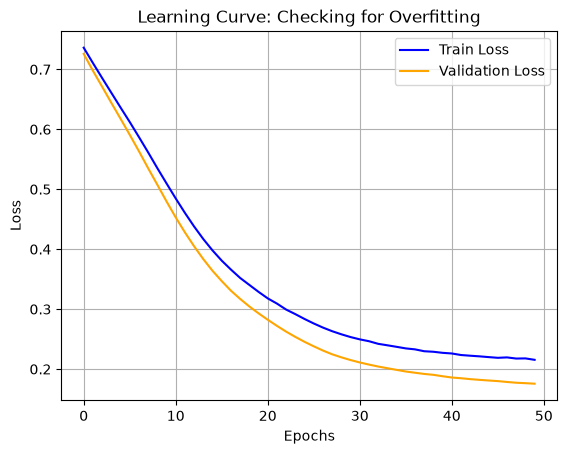

In [15]:
plt.Figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss', color='blue')
plt.plot(val_losses, label='Validation Loss', color='orange')
plt.title('Learning Curve: Checking for Overfitting')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

In [16]:
try:
    ckpt = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=True)
except:
    ckpt = torch.load(CHECKPOINT_PATH, map_location='cpu')

model.load_state_dict(ckpt)
print(f'Training Complete! Loaded best checkpoint (val loss {best_val_loss:.4f}).')

Training Complete! Loaded best checkpoint (val loss 0.1756).


In [18]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_proba = torch.sigmoid(test_logits).numpy().ravel()
    y_true = y_test_t.numpy().ravel()
    y_pred = (test_proba >= 0.5).astype(int)

print(f'y pred: {y_pred}')

print('\n----- Test set metrics -----')
print(classification_report(y_true, y_pred, zero_division=0))

print('Classification matrix [ [TN, FP], [FN, TP] ]:')
print(confusion_matrix(y_true, y_pred))

y pred: [0 0 1 0 0 1 0 0 0 0 1 1 0 1 1 1 1 0 1 0 0 0 1 0 1 0 1 0 1 0 0 0 1 1 1 1 0
 1 1 1 1 1 0 1 1 0 1 1 1 1 0 1 0 1 1 0 0 0 1 1 0 0 0 0 0 0 1 0 1 1 0 0 0 0
 0 0 0 1 1 0 1 0 1 0 1 1 1 1 0 0 0 0 0 1 1 0 1 1 1 0 1 1 0 1 1 0 0 0 1 0 0
 1 1 1 0 0 0 1 0 0 0 1 0 1 0 1 0 1 0 1 0 0 1 0 0 0 0 0 0 1 0 1 1 1 1 1 0 0
 1 0]

----- Test set metrics -----
              precision    recall  f1-score   support

         0.0       0.92      0.97      0.95        75
         1.0       0.97      0.92      0.95        75

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Classification matrix [ [TN, FP], [FN, TP] ]:
[[73  2]
 [ 6 69]]
